# Звезда Барнарда: положение на заданную дату

Учебный расчёт для **Gaia DR3 4472832130942575872**. Результат — **барицентрические астрометрические координаты ICRS**, без годичного параллакса.

Блокнот рассчитан на начинающего пользователя Python: нужны базовое знакомство с координатами RA/Dec и установленное окружение из `BARNARD_MOTION.md`. После установки каталог и интернет не требуются. Все вычисления выполняют функции `barnard_motion.py`.

Порядок: 1) исходная запись; 2) дата и результат; 3) две учебные даты; 4) график; 5) упражнение. Демонстрационные даты **не являются выбранными снимками SPHEREx**.

In [1]:
from pathlib import Path
import sys

# Работает при запуске из корня проекта и из папки этого блокнота.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "barnard_motion.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Откройте блокнот из папки проекта: см. BARNARD_MOTION.md")
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import astropy.units as u
from astropy.table import Table
from IPython.display import display
from barnard_motion import (load_source, parse_time, Observation, coordinate_at,
                            predict, calculate_observation, calculate_observations,
                            load_observations, write_results, tangent_offsets_mas)

source = load_source(ROOT / "OBJECT_PARAMETERS.csv")
print(f"Gaia DR3 {source.source_id}; эпоха J{source.epoch.tcb.jyear:.1f} TCB")

Matplotlib is building the font cache; this may take a moment.


Gaia DR3 4472832130942575872; эпоха J2016.0 TCB


## 1. Исходные параметры

Одна запись содержит согласованные координаты, собственное движение, параллакс и лучевую скорость. `pmra` означает **μα⋆ = (dα/dt) cos δ**, а ошибка RA — **σα⋆ = σα cos δ**. Именно такие величины ожидает реализация; повторно умножать `pmra` на cos δ нельзя.

Положительный RV означает удаление; отрицательный RV Барнарда означает приближение. По мере изменения расстояния меняется угловая скорость: это перспективное ускорение.

In [2]:
parameter_table = Table(rows=[
    ("RA α", source.values[0], source.row["ra_error_mas"], "deg; ошибка mas (α⋆)"),
    ("Dec δ", source.values[1], source.row["dec_error_mas"], "deg; ошибка mas"),
    ("Параллакс ϖ", source.values[2], source.row["parallax_error_mas"], "mas"),
    ("μα⋆", source.values[3], source.row["pmra_error_mas_yr"], "mas/yr"),
    ("μδ", source.values[4], source.row["pmdec_error_mas_yr"], "mas/yr"),
    ("RV", source.values[5], source.row["radial_velocity_error_km_s"], "km/s"),
], names=["Параметр", "Значение", "Формальная ошибка 1σ", "Единицы"])
display(parameter_table)
print("Исходная запись Gaia:", source.source_url)

Параметр,Значение,Формальная ошибка 1σ,Единицы
str11,float64,str11,str20
RA α,269.44850252543836,0.026238997,deg; ошибка mas (α⋆)
Dec δ,4.739420051112412,0.029043527,deg; ошибка mas
Параллакс ϖ,546.975939730948,0.040116355,mas
μα⋆,-801.5509783684709,0.031820867,mas/yr
μδ,10362.394206546573,0.036070455,mas/yr
RV,-110.46822,0.13125522,km/s


Исходная запись Gaia: https://gea.esac.esa.int/tap-server/tap/sync?REQUEST=doQuery&LANG=ADQL&FORMAT=csv&QUERY=SELECT+%2A+FROM+gaiadr3.gaia_source+WHERE+source_id+%3D+4472832130942575872


### Как переносятся ошибки

Порядок входных возмущений: **(δα⋆, δδ, δϖ, δμα⋆, δμδ, δRV)**. Первые три величины в mas, две следующие в mas/год, RV в км/с. Ковариация пяти параметров восстанавливается как `Cᵢⱼ = ρᵢⱼ σᵢ σⱼ`; RV добавляется независимо, с нулевыми корреляциями с астрометрией.

Скрипт вычисляет центральными разностями Якобиан `J` размера 2×6 и `C_out = J C_in Jᵀ`. Выходные оси — локальные восток/север в перенесённой точке, то есть дифференциалы **dα cos δ, dδ**. При возмущении RA множитель cos δ берётся на исходной эпохе. Все десять корреляций Gaia используются; диагональное приближение не применяется.

In [3]:
sigmas = np.sqrt(np.diag(source.covariance))
corr = source.covariance / np.outer(sigmas, sigmas)
display(Table(np.round(corr[:5, :5], 4), names=["α⋆", "δ", "ϖ", "μα⋆", "μδ"]))
print("Строки и столбцы: α⋆, δ, ϖ, μα⋆, μδ; RV — независимая шестая величина.")

α⋆,δ,ϖ,μα⋆,μδ
float64,float64,float64,float64,float64
1.0,-0.0523,0.0483,-0.2111,-0.0347
-0.0523,1.0,-0.5435,-0.0558,-0.6312
0.0483,-0.5435,1.0,-0.0578,0.5594
-0.2111,-0.0558,-0.0578,1.0,0.0306
-0.0347,-0.6312,0.5594,0.0306,1.0


Строки и столбцы: α⋆, δ, ϖ, μα⋆, μδ; RV — независимая шестая величина.


## 2. Выбор даты и результат

По умолчанию ISO-дата интерпретируется в UTC, независимо от часового пояса компьютера. Для числовой даты обязательны **и формат, и шкала**. Допустимы ISO/ISOT, MJD, юлианский год; шкалы UTC, TAI, TT, TCG, TDB, TCB. `J2025.0` означает числовой `2025.0` с форматом `jyear`, а не календарный 1 января.

Для MJD замените три значения ниже, например на `60800.0`, `mjd`, `utc`. Значение MJD здесь только пример формата.

In [4]:
date_value = "2025-04-01T00:00:00"
date_format = "iso"
date_scale = "utc"
selected_time = parse_time(date_value, date_format, date_scale)
selected = Observation(selected_time, metadata={"is_demo": "true"})
result = calculate_observation(source, selected)
summary_columns = ["time_utc", "time_tcb", "ra_deg", "dec_deg",
                   "sigma_alpha_star_mas", "sigma_delta_mas", "ra_dec_corr",
                   "parallax_scale_1au_mas", "parallax_applied"]
display(Table(rows=[result])[summary_columns])
print("ICRS: барицентрическая астрометрическая позиция; годичный параллакс не применён.")

time_utc,time_tcb,ra_deg,dec_deg,sigma_alpha_star_mas,sigma_delta_mas,ra_dec_corr,parallax_scale_1au_mas,parallax_applied
str30,str29,float64,float64,float64,float64,float64,float64,str5
2025-04-01T00:00:00.000000000Z,2025-04-01T00:01:32.792994425,269.44643530671595,4.766052498517327,0.29007705231136754,0.32499805385835795,0.01843974581428546,547.2887142690361,false


ICRS: барицентрическая астрометрическая позиция; годичный параллакс не применён.


### Что означает масштаб параллакса

`parallax_scale_1au_mas` — **1000 / distance_pc** после переноса, характерный угловой масштаб базы 1 а.е. Это не поправка RA или Dec: её направление и величина для кадра зависят от положения наблюдателя. Расстояние участвует в модели пространственного движения, хотя годичный параллакс к координатам не применяется.

Ошибки в таблице — формальные 1σ в двух локальных угловых компонентах, не полная ошибка предсказания и не радиус круговой области.

In [5]:
epoch_check = predict(source, source.epoch)
print("Ошибки на исходной эпохе, mas:", np.sqrt(np.diag(epoch_check.covariance_mas2)))
np.testing.assert_allclose(np.sqrt(np.diag(epoch_check.covariance_mas2)),
                           np.sqrt(np.diag(source.covariance))[:2], rtol=0.01)
print("Исходные формальные ошибки воспроизведены в пределах 1%.")

Ошибки на исходной эпохе, mas: [0.026239   0.02904353]
Исходные формальные ошибки воспроизведены в пределах 1%.


## 3. Сравнение 1 апреля и 1 октября 2025 года

Оба момента — **00:00 UTC**. Учебный CSV содержит `is_demo=true` и пустые `obs_id`; реальные идентификаторы не придуманы.

Для реальных данных замените путь на заполненный `data/barnard_observations_template.csv`. В каждой строке нужны `time_format`, `time_scale` и либо `time`, либо пара `t_min`, `t_max`. Интервал усредняется в непрерывной шкале TAI средствами Astropy. Время наблюдения не заменяется датой публикации.

In [6]:
demo_observations = load_observations(ROOT / "data/barnard_observations_demo.csv")
demo_results = calculate_observations(source, demo_observations)
write_results(demo_results, ROOT / "output/barnard_demo_positions.csv")
display(Table(rows=demo_results)[["obs_id", "is_demo", "time_utc", "ra_deg", "dec_deg",
                                  "sigma_alpha_star_mas", "sigma_delta_mas"]])
first = coordinate_at(source, demo_observations[0].time)
last = coordinate_at(source, demo_observations[1].time)
shift = tangent_offsets_mas(first, last) / 1000
print(f"Смещение в локальной системе первой даты: восток {shift[0]:+.6f}″, север {shift[1]:+.6f}″")
print(f"Угловое расстояние: {first.separation(last).to_value(u.arcsec):.6f}″")
assert demo_results[0]["ra_deg"] == result["ra_deg"] if date_value == "2025-04-01T00:00:00" and date_format == "iso" and date_scale == "utc" else True

obs_id,is_demo,time_utc,ra_deg,dec_deg,sigma_alpha_star_mas,sigma_delta_mas
str1,str4,str30,float64,float64,float64,float64
,true,2025-04-01T00:00:00.000000000Z,269.44643530671595,4.766052498517327,0.29007705231136754,0.32499805385835795
,true,2025-10-01T00:00:00.000000000Z,269.4463232284464,4.767496369207187,0.30598900580388244,0.3443984260246346


Смещение в локальной системе первой даты: восток -0.402086″, север +5.197935″
Угловое расстояние: 5.213463″


За эти полгода звезда перемещается преимущественно к северу и немного к западу. Для такого интервала локальное восточное смещение практически равно Δα cos δ первой точки. Указанные компоненты — сферические смещения относительно первой даты; формальные ошибки каждой даты вычисляются в её собственной касательной плоскости.

Ошибки двух эпох **коррелированы**, поскольку происходят из одной записи Gaia. Ошибку разности нельзя получать простым сложением независимых дисперсий; ниже выводится только само смещение.

## 4. График движения

Кривая использует ту же функцию `coordinate_at`, что и основной расчёт. Начало смещений — 1 апреля 2025 года. На графике нет сезонной параллактической петли, поскольку годичный параллакс отключён.

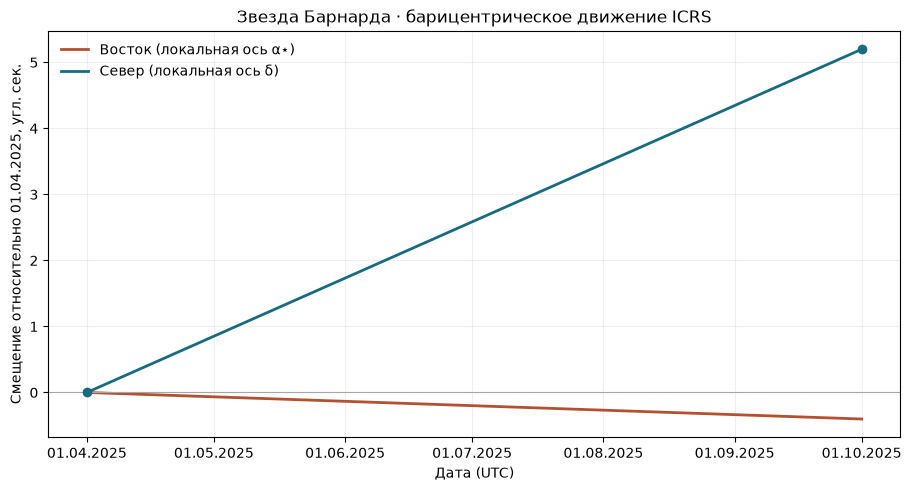

In [7]:
times = demo_observations[0].time.tai + np.linspace(0, 1, 80) * (
    demo_observations[1].time.tai - demo_observations[0].time.tai)
positions = [coordinate_at(source, t) for t in times]
offsets = np.array([tangent_offsets_mas(first, p) for p in positions]) / 1000

fig, ax = plt.subplots(figsize=(9, 4.8), layout="constrained")
ax.plot(times.utc.to_datetime(), offsets[:, 0], label="Восток (локальная ось α⋆)", color="#b25031", linewidth=2)
ax.plot(times.utc.to_datetime(), offsets[:, 1], label="Север (локальная ось δ)", color="#176b80", linewidth=2)
ax.scatter([times[0].utc.to_datetime(), times[-1].utc.to_datetime()], offsets[[0, -1], 1], color="#176b80", zorder=3)
ax.axhline(0, color="0.65", linewidth=0.8)
ax.set(title="Звезда Барнарда · барицентрическое движение ICRS",
       xlabel="Дата (UTC)", ylabel="Смещение относительно 01.04.2025, угл. сек.")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m.%Y"))
ax.grid(alpha=0.2)
ax.legend(frameon=False)
fig.savefig(ROOT / "output/barnard_motion_demo.png", dpi=170)
plt.show()

## 5. Короткое упражнение

Измените дату ниже на **1 апреля 2026 года, 00:00 UTC**. До запуска предположите направление и порядок смещения относительно 1 апреля 2025 года. Затем сравните масштаб параллакса: при приближении звезды он немного увеличивается.

Дополнительная задача: задайте тот же момент через MJD и UTC и проверьте совпадение координат. Не забывайте множитель cos δ при интерпретации компоненты RA.

In [8]:
exercise_date = "2026-04-01T00:00:00"  # Измените дату и запустите ячейку.
exercise_time = parse_time(exercise_date)
exercise_result = calculate_observation(source, Observation(exercise_time, metadata={"is_demo": "true"}))
exercise_position = coordinate_at(source, exercise_time)
print("Смещение (восток, север), угл. сек.:", tangent_offsets_mas(first, exercise_position) / 1000)
print("Масштаб параллакса на базе 1 а.е., mas:", exercise_result["parallax_scale_1au_mas"])
equivalent_time = parse_time(f"{exercise_time.utc.mjd:.14f}", "mjd", "utc")
assert exercise_position.separation(coordinate_at(source, equivalent_time)).to_value(u.mas) < 0.001

Смещение (восток, север), угл. сек.: [-0.8019991  10.36778439]
Масштаб параллакса на базе 1 а.е., mas: 547.3225294961803


## Ограничения и переход к снимкам

- Постоянная пространственная скорость через `SkyCoord.apply_space_motion` учитывает перспективное изменение углового движения; это не модель орбит или произвольных ускорений.
- Нет поправки нулевой точки параллакса, дополнительного увеличения ошибок Gaia, систематик RV, неопределённости времени, WCS и измерения центра изображения. Параллакс инвертируется напрямую при высоком отношении сигнал/ошибка этой записи.
- Нет поправки на положение SPHEREx, годичного параллакса, аберрации и гравитационного отклонения для конкретного наблюдателя. Результат не является готовой видимой позицией на детекторе.
- Полученные от Айгерим файлы `table_Spectral-Images (1).tbl` и `table.tbl` описывают другую область неба: центры RA 294–298°, Dec −17…−13°. Они не используются как кадры Барнарда. `table.tbl` — карточка одного наблюдения из первого файла. Формат времени в ней MJD, шкала не указана; ссылки ведут на DataLink.

Для сравнения с кадром нужны подтверждённые ID, времена и шкалы, детектор/выпуск, положение наблюдателя и соглашения пространственной привязки. Поиск IRSA, загрузка/чтение FITS и измерение центра остаются следующим этапом.

Источники: [метод Astropy](https://docs.astropy.org/en/stable/coordinates/apply_space_motion.html), [параметры Gaia DR3](https://gea.esac.esa.int/archive/documentation/GDR3/Gaia_archive/chap_datamodel/sec_dm_main_source_catalogue/ssec_dm_gaia_source.html), [введение SPHEREx/IRSA](https://caltech-ipac.github.io/irsa-tutorials/spherex-intro/). Подробности запуска и выходных колонок — в `BARNARD_MOTION.md`.